# Web Data Collection and Comparative Analysis Using World Bank Data
**Course:** CSE 4357 – Principles & Techniques of Data Science (Fall 2026)
**Instructor:** Momtazul Arefin Labib

**Student:** Samia Akter Mumu
**Countries:** Switzerland (CHE) and Austria (AUT)

**Indicators:** Population, total (`SP.POP.TOTL`), GDP per capita, current US$ (`NY.GDP.PCAP.CD`), Life expectancy at birth (`SP.DYN.LE00.IN`)
**Period:** 2000–2023 (inclusive)

## 0. Configuration & Imports

In [1]:
# configuration cell
import requests
import pandas as pd
import matplotlib.pyplot as plt

# ====== Student configuration ======
STUDENT_NAME = "samia_akter_mumu"  # used for the CSV file name
COUNTRY_1 = "CHE"                   # Switzerland
COUNTRY_2 = "AUT"                   # Austria
# =========================================

START_YEAR, END_YEAR = 2000, 2023
INDICATORS = {
    "SP.POP.TOTL": "Population, total",
    "NY.GDP.PCAP.CD": "GDP per capita (current US$)",
    "SP.DYN.LE00.IN": "Life expectancy at birth, total (years)",
}
BASE_URL = "https://api.worldbank.org/v2/country/{country}/indicator/{indicator}"
api_urls_used = []   # Task 1.5: record of every API URL requested
print("Countries:", COUNTRY_1, "and", COUNTRY_2)

Countries: CHE and AUT


## Task 1: Data Collection
HTTP GET requests are sent to the World Bank Indicators API (one request per country per indicator).
The HTTP status code and the JSON structure are checked, and request errors are handled with `try/except`.

In [2]:
# data collection function
def fetch_indicator(country, indicator, start=START_YEAR, end=END_YEAR):
    """Fetch one indicator for one country from the World Bank API and return a list of records."""
    url = BASE_URL.format(country=country, indicator=indicator)
    params = {"format": "json", "date": f"{start}:{end}", "per_page": 1000}
    try:
        response = requests.get(url, params=params, timeout=30)
        api_urls_used.append(response.url)          # record the full URL
        print(f"[{response.status_code}] {response.url}")
        response.raise_for_status()                 # raises for 4xx / 5xx
        payload = response.json()
    except requests.exceptions.Timeout:
        print(f"Timeout while requesting {country} / {indicator}")
        return []
    except requests.exceptions.RequestException as e:
        print(f"Request failed for {country} / {indicator}: {e}")
        return []
    except ValueError:
        print(f"Response for {country} / {indicator} was not valid JSON")
        return []

    # a valid response is [metadata, data]; errors come back as [{'message': [...]}]
    if not isinstance(payload, list) or len(payload) < 2 or payload[1] is None:
        print(f"No data returned for {country} / {indicator}: {payload}")
        return []

    records = []
    for item in payload[1]:
        records.append({
            "country_name": item["country"]["value"],
            "country_code": item["countryiso3code"] or country,
            "year": item["date"],
            "indicator_name": item["indicator"]["value"],
            "indicator_code": item["indicator"]["id"],
            "value": item["value"],
        })
    return records

all_records = []
for country in (COUNTRY_1, COUNTRY_2):
    for code_, name in INDICATORS.items():
        all_records.extend(fetch_indicator(country, code_))
print("\nTotal records collected:", len(all_records))

[200] https://api.worldbank.org/v2/country/CHE/indicator/SP.POP.TOTL?format=json&date=2000%3A2023&per_page=1000
[200] https://api.worldbank.org/v2/country/CHE/indicator/NY.GDP.PCAP.CD?format=json&date=2000%3A2023&per_page=1000
[200] https://api.worldbank.org/v2/country/CHE/indicator/SP.DYN.LE00.IN?format=json&date=2000%3A2023&per_page=1000
[200] https://api.worldbank.org/v2/country/AUT/indicator/SP.POP.TOTL?format=json&date=2000%3A2023&per_page=1000
[200] https://api.worldbank.org/v2/country/AUT/indicator/NY.GDP.PCAP.CD?format=json&date=2000%3A2023&per_page=1000
[200] https://api.worldbank.org/v2/country/AUT/indicator/SP.DYN.LE00.IN?format=json&date=2000%3A2023&per_page=1000

Total records collected: 144


In [3]:
# Task 1.5: API URLs used
print("API URLs used for data collection:")
for i, u in enumerate(api_urls_used, 1):
    print(f"{i}. {u}")

API URLs used for data collection:
1. https://api.worldbank.org/v2/country/CHE/indicator/SP.POP.TOTL?format=json&date=2000%3A2023&per_page=1000
2. https://api.worldbank.org/v2/country/CHE/indicator/NY.GDP.PCAP.CD?format=json&date=2000%3A2023&per_page=1000
3. https://api.worldbank.org/v2/country/CHE/indicator/SP.DYN.LE00.IN?format=json&date=2000%3A2023&per_page=1000
4. https://api.worldbank.org/v2/country/AUT/indicator/SP.POP.TOTL?format=json&date=2000%3A2023&per_page=1000
5. https://api.worldbank.org/v2/country/AUT/indicator/NY.GDP.PCAP.CD?format=json&date=2000%3A2023&per_page=1000
6. https://api.worldbank.org/v2/country/AUT/indicator/SP.DYN.LE00.IN?format=json&date=2000%3A2023&per_page=1000


## Task 2: Data Processing and Cleaning

In [4]:
# build the DataFrame
df = pd.DataFrame(all_records)
df = df[["country_name", "country_code", "year", "indicator_name", "indicator_code", "value"]]
print(df.shape)
df.head(10)

(144, 6)


,country_name,country_code,year,indicator_name,indicator_code,value
0,Switzerland,CHE,2023,"Population, total",SP.POP.TOTL,8888822.0
1,Switzerland,CHE,2022,"Population, total",SP.POP.TOTL,8777088.0
2,Switzerland,CHE,2021,"Population, total",SP.POP.TOTL,8704546.0
3,Switzerland,CHE,2020,"Population, total",SP.POP.TOTL,8638167.0
4,Switzerland,CHE,2019,"Population, total",SP.POP.TOTL,8575280.0
5,Switzerland,CHE,2018,"Population, total",SP.POP.TOTL,8514329.0
6,Switzerland,CHE,2017,"Population, total",SP.POP.TOTL,8451840.0
7,Switzerland,CHE,2016,"Population, total",SP.POP.TOTL,8373338.0
8,Switzerland,CHE,2015,"Population, total",SP.POP.TOTL,8282396.0
9,Switzerland,CHE,2014,"Population, total",SP.POP.TOTL,8188649.0


### 2.3 Data types (before conversion)

In [5]:
print(df.dtypes)

country_name       object
country_code       object
year               object
indicator_name     object
indicator_code     object
value             float64
dtype: object


In [6]:
# Convert to proper types
df["year"] = df["year"].astype(int)
df["value"] = pd.to_numeric(df["value"], errors="coerce")
print(df.dtypes)

country_name       object
country_code       object
year                int64
indicator_name     object
indicator_code     object
value             float64
dtype: object


### 2.4 Missing values and duplicates

In [7]:
print("Missing values per column:")
print(df.isna().sum())

print("\nDuplicate records (same country, year, indicator):",
      df.duplicated(subset=["country_code", "year", "indicator_code"]).sum())
print("Fully duplicated rows:", df.duplicated().sum())

missing = df[df["value"].isna()].sort_values(["country_code", "indicator_code", "year"])
print("\nMissing observations:", len(missing))
missing[["country_name", "country_code", "year", "indicator_name"]]

Missing values per column:
country_name      0
country_code      0
year              0
indicator_name    0
indicator_code    0
value             0
dtype: int64

Duplicate records (same country, year, indicator): 0
Fully duplicated rows: 0

Missing observations: 0


,country_name,country_code,year,indicator_name


### 2.5 Handling missing values – approach
* No values are invented, interpolated or filled in (as required by the assignment).
* Missing observations are listed above and kept as `NaN`.
* If any year has a missing value for **either country in any indicator**, that year is removed for **both** countries so the comparison covers the **same period**. The resulting period is printed and documented below.
* Exact duplicates (if any) are removed.

In [8]:
# cleaning
df_clean = df.drop_duplicates(subset=["country_code", "year", "indicator_code"]).copy()

# years with a complete set of observations (2 countries x 3 indicators)
complete = df_clean.groupby("year")["value"].apply(lambda s: s.notna().all())
valid_years = sorted(complete[complete].index)
dropped_years = sorted(set(df_clean["year"]) - set(valid_years))

df_clean = df_clean[df_clean["year"].isin(valid_years)].reset_index(drop=True)
print("Years dropped because of missing data:", dropped_years if dropped_years else "None")
print(f"Final comparison period: {min(valid_years)}–{max(valid_years)} ({len(valid_years)} years)")
print("Remaining missing values:", df_clean["value"].isna().sum())

Years dropped because of missing data: None
Final comparison period: 2000–2023 (24 years)
Remaining missing values: 0


### 2.6 Save the cleaned dataset

In [9]:
csv_name = f"{STUDENT_NAME}_world_bank_data.csv"
df_clean.to_csv(csv_name, index=False)
print("Saved:", csv_name)
df_clean.head()

Saved: samia_akter_mumu_world_bank_data.csv


,country_name,country_code,year,indicator_name,indicator_code,value
0,Switzerland,CHE,2023,"Population, total",SP.POP.TOTL,8888822.0
1,Switzerland,CHE,2022,"Population, total",SP.POP.TOTL,8777088.0
2,Switzerland,CHE,2021,"Population, total",SP.POP.TOTL,8704546.0
3,Switzerland,CHE,2020,"Population, total",SP.POP.TOTL,8638167.0
4,Switzerland,CHE,2019,"Population, total",SP.POP.TOTL,8575280.0


## Task 3: Comparative Analysis and Visualization

In [10]:
# reshape to wide format for analysis
wide = df_clean.pivot_table(index=["year", "country_name"], columns="indicator_code", values="value").reset_index()
wide = wide.rename(columns={"SP.POP.TOTL": "population",
                            "NY.GDP.PCAP.CD": "gdp_per_capita",
                            "SP.DYN.LE00.IN": "life_expectancy"})
countries = wide["country_name"].unique().tolist()
y0, y1 = wide["year"].min(), wide["year"].max()
wide.head()

indicator_code,year,country_name,gdp_per_capita,life_expectancy,population
0,2000,Austria,24487.297469,78.126829,8011566.0
1,2000,Switzerland,39298.096804,79.680488,7184250.0
2,2001,Austria,24430.495983,78.575610,8042293.0
3,2001,Switzerland,40133.610197,80.180488,7229854.0
4,2002,Austria,26334.862215,78.678049,8081957.0


### Q1. Which country experienced greater population growth?

In [11]:
rows = []
for c in countries:
    d = wide[wide.country_name == c].set_index("year")
    p0, p1 = d.loc[y0, "population"], d.loc[y1, "population"]
    cagr = ((p1 / p0) ** (1 / (y1 - y0)) - 1) * 100
    rows.append({"Country": c, f"Pop {y0}": p0, f"Pop {y1}": p1,
                 "Absolute growth": p1 - p0, "Growth %": (p1 / p0 - 1) * 100, "CAGR %": cagr})
pop_tbl = pd.DataFrame(rows)
display(pop_tbl.round(2))
a = pop_tbl.loc[pop_tbl["Absolute growth"].idxmax(), "Country"]
r = pop_tbl.loc[pop_tbl["Growth %"].idxmax(), "Country"]
print(f"Greater ABSOLUTE population growth: {a}")
print(f"Greater PERCENTAGE population growth: {r}")

,Country,Pop 2000,Pop 2023,Absolute growth,Growth %,CAGR %
0,Austria,8011566.0,9131761.0,1120195.0,13.98,0.57
1,Switzerland,7184250.0,8888822.0,1704572.0,23.73,0.93


Greater ABSOLUTE population growth: Switzerland
Greater PERCENTAGE population growth: Switzerland


### Q2. Which country had the higher GDP per capita, and how did the difference change?

In [12]:
gdp = wide.pivot(index="year", columns="country_name", values="gdp_per_capita")
c1, c2 = countries
gdp["difference"] = gdp[c1] - gdp[c2]
gdp["ratio"] = gdp[c1] / gdp[c2]
display(gdp.round(2))
print("Years in which each country had the higher GDP per capita:")
print(gdp[[c1, c2]].idxmax(axis=1).value_counts())
print(f"\nGap in {y0}: {gdp.loc[y0, 'difference']:,.2f} US$   |   Gap in {y1}: {gdp.loc[y1, 'difference']:,.2f} US$")
print("Absolute gap", "widened" if abs(gdp.loc[y1, 'difference']) > abs(gdp.loc[y0, 'difference']) else "narrowed", "over the period.")

country_name,Austria,Switzerland,difference,ratio
year,,,,
2000,24487.30,39298.10,-14810.80,0.62
2001,24430.50,40133.61,-15703.11,0.61
2002,26334.86,43094.25,-16759.39,0.61
2003,32110.12,49947.39,-17837.28,0.64
2004,36614.25,55349.62,-18735.37,0.66
2005,38157.37,57080.07,-18922.70,0.67
2006,40382.21,59910.29,-19528.09,0.67
2007,46622.96,66082.12,-19459.16,0.71
2008,51581.40,75147.54,-23566.14,0.69


Years in which each country had the higher GDP per capita:
Switzerland    24
Name: count, dtype: int64

Gap in 2000: -14,810.80 US$   |   Gap in 2023: -47,870.25 US$
Absolute gap widened over the period.


### Q3. Which country experienced a greater improvement in life expectancy?

In [13]:
le = wide.pivot(index="year", columns="country_name", values="life_expectancy")
le_tbl = pd.DataFrame({"Life exp. " + str(y0): le.loc[y0], "Life exp. " + str(y1): le.loc[y1]})
le_tbl["Improvement (years)"] = le_tbl.iloc[:, 1] - le_tbl.iloc[:, 0]
display(le_tbl.round(2))
print("Greater improvement in life expectancy:", le_tbl["Improvement (years)"].idxmax())

,Life exp. 2000,Life exp. 2023,Improvement (years)
country_name,,,
Austria,78.13,81.79,3.67
Switzerland,79.68,84.16,4.48


Greater improvement in life expectancy: Switzerland


### Visualizations

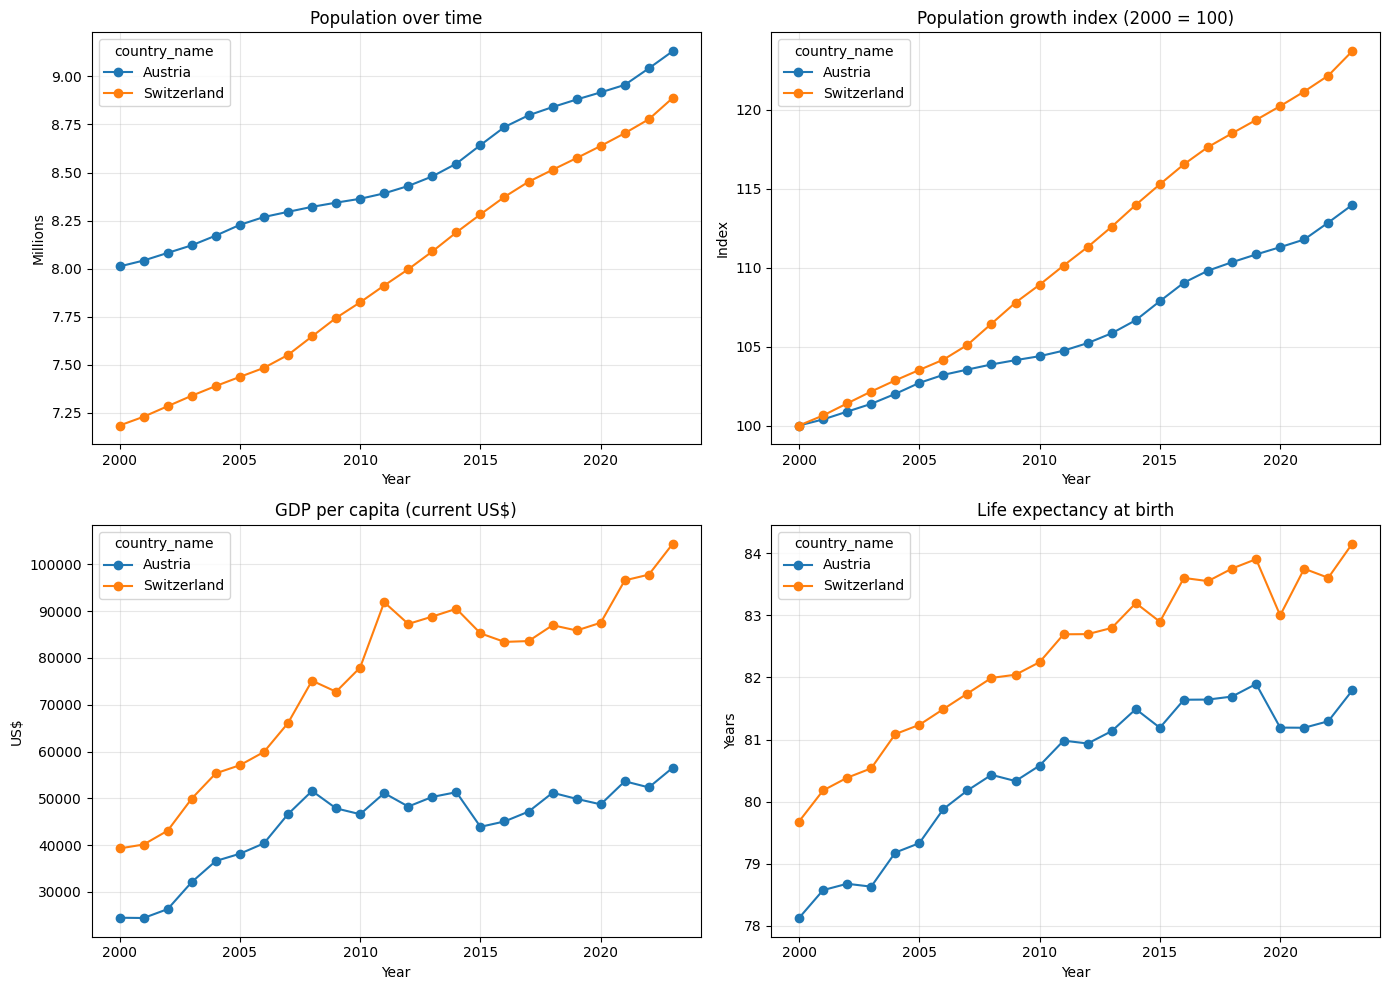

In [14]:
# visualizations
pop = wide.pivot(index="year", columns="country_name", values="population")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Population trend
(pop / 1e6).plot(ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Population over time"); axes[0, 0].set_ylabel("Millions")

# 2. Indexed population growth (start year = 100)
(pop / pop.iloc[0] * 100).plot(ax=axes[0, 1], marker="o")
axes[0, 1].set_title(f"Population growth index ({y0} = 100)"); axes[0, 1].set_ylabel("Index")

# 3. GDP per capita
gdp[[c1, c2]].plot(ax=axes[1, 0], marker="o")
axes[1, 0].set_title("GDP per capita (current US$)"); axes[1, 0].set_ylabel("US$")

# 4. Life expectancy
le.plot(ax=axes[1, 1], marker="o")
axes[1, 1].set_title("Life expectancy at birth"); axes[1, 1].set_ylabel("Years")

for ax in axes.flat:
    ax.set_xlabel("Year"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

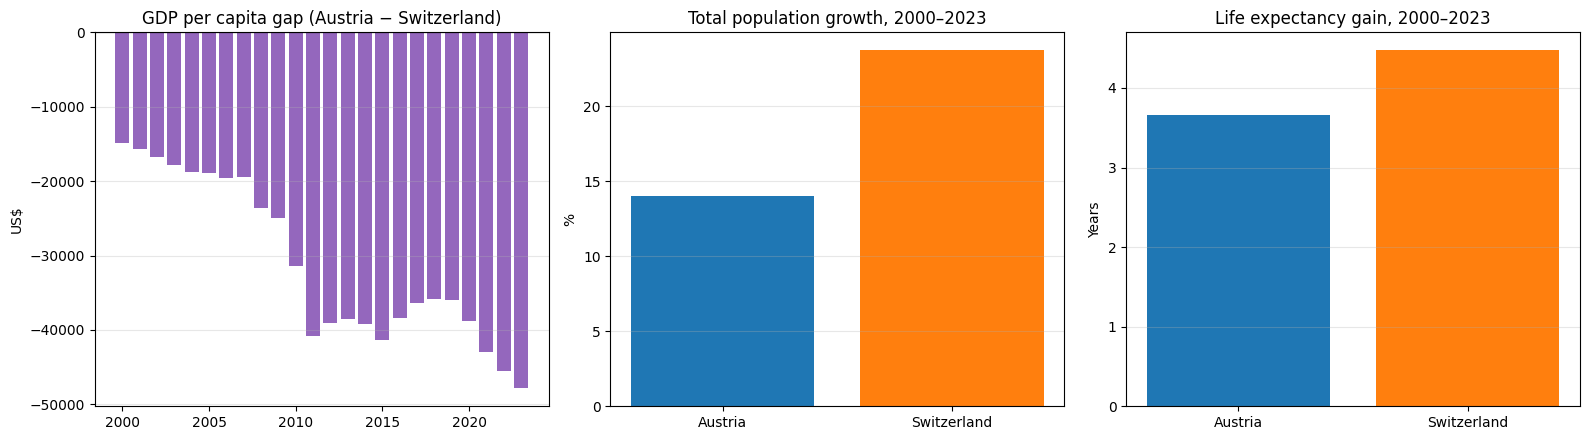

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# GDP per capita gap over time
axes[0].bar(gdp.index, gdp["difference"], color="tab:purple")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title(f"GDP per capita gap ({c1} − {c2})"); axes[0].set_ylabel("US$")

# Population growth % comparison
axes[1].bar(pop_tbl["Country"], pop_tbl["Growth %"], color=["tab:blue", "tab:orange"])
axes[1].set_title(f"Total population growth, {y0}–{y1}"); axes[1].set_ylabel("%")

# Life expectancy improvement
axes[2].bar(le_tbl.index, le_tbl["Improvement (years)"], color=["tab:blue", "tab:orange"])
axes[2].set_title(f"Life expectancy gain, {y0}–{y1}"); axes[2].set_ylabel("Years")

for ax in axes: ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## Summary of Findings

In [16]:
# auto-generated summary
print(f"Period analysed: {y0}–{y1}")
print(f"1. Population: {r} grew faster in % terms ({pop_tbl['Growth %'].max():.1f}%); {a} added more people in absolute terms.")
higher = gdp[[c1, c2]].iloc[-1].idxmax()
print(f"2. GDP per capita: {higher} was higher in {y1}; gap went from {gdp.loc[y0,'difference']:,.0f} to {gdp.loc[y1,'difference']:,.0f} US$ ({c1} minus {c2}).")
print(f"3. Life expectancy: {le_tbl['Improvement (years)'].idxmax()} improved more ({le_tbl['Improvement (years)'].max():.2f} years).")
print("Missing-data handling: no values were imputed; incomplete years (if any) were removed for both countries:",
      dropped_years if dropped_years else "none")

Period analysed: 2000–2023
1. Population: Switzerland grew faster in % terms (23.7%); Switzerland added more people in absolute terms.
2. GDP per capita: Switzerland was higher in 2023; gap went from -14,811 to -47,870 US$ (Austria minus Switzerland).
3. Life expectancy: Switzerland improved more (4.48 years).
Missing-data handling: no values were imputed; incomplete years (if any) were removed for both countries: none
